In [17]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [18]:
import os
from pathlib import Path

# Chặn lỗi tạo thư mục giả khi Drive chưa mount
assert os.path.exists('/content/drive/MyDrive/lab_ATvsBMTT'), "Drive chưa mount, quay lại bước mount"

OUT_DIR = Path('/content/drive/MyDrive/violence_project')
DATA    = Path('/content/data')
for p in (OUT_DIR/'splits', OUT_DIR/'checkpoints', DATA):
    p.mkdir(parents=True, exist_ok=True)

zips = sorted(Path('/content/drive/MyDrive/lab_ATvsBMTT').rglob('dataset-*.zip'))
for z in zips:
    print(z, round(z.stat().st_size / 1e9, 2), 'GB')

/content/drive/MyDrive/lab_ATvsBMTT/đồ án môn/Dataset/dataset-20261018T113953Z-1-001.zip 2.14 GB
/content/drive/MyDrive/lab_ATvsBMTT/đồ án môn/Dataset/dataset-20261018T113953Z-1-002.zip 0.04 GB


In [19]:
import zipfile
for z in zips:
    print('Giải nén', z.name)
    with zipfile.ZipFile(z) as f:
        f.extractall(DATA)
!du -sh /content/data
!find /content/data -maxdepth 4 -type d | head -30

Giải nén dataset-20261018T113953Z-1-001.zip
Giải nén dataset-20261018T113953Z-1-002.zip
2.1G	/content/data
/content/data
/content/data/dataset
/content/data/dataset/Hockey
/content/data/dataset/Real Life Violence Dataset
/content/data/dataset/Real Life Violence Dataset/Violence
/content/data/dataset/Real Life Violence Dataset/NonViolence


In [ ]:
!pip install -q transformers accelerate evaluate opencv-python-headless tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.4 MB/s eta 0:00:00


In [20]:
import cv2, pandas as pd
from tqdm.auto import tqdm
VID_EXT = {'.mp4', '.avi', '.mov', '.mkv'}

def probe(path):
    cap = cv2.VideoCapture(str(path))
    ok = cap.isOpened()
    n   = int(cap.get(cv2.CAP_PROP_FRAME_COUNT)) if ok else 0
    fps = cap.get(cv2.CAP_PROP_FPS) if ok else 0
    w   = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)) if ok else 0
    h   = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)) if ok else 0
    can_read = False
    if ok:
        if n > 1:
            cap.set(cv2.CAP_PROP_POS_FRAMES, n // 2)
        can_read, _ = cap.read()
    cap.release()
    return dict(frames=n, fps=round(fps, 2), w=w, h=h,
                ok=bool(ok and can_read and n >= 16))

# Nhãn RLVS theo tên thư mục cha (kiểm tra NonViolence trước vì nó chứa chữ 'violence')
rlvs_files = [p for p in DATA.rglob('*')
              if p.suffix.lower() in VID_EXT and 'real life' in str(p).lower()]

def rlvs_label(p):
    parent = p.parent.name.lower()
    return 0 if ('nonviolence' in parent or 'non_violence' in parent) else 1

rows = []
for p in tqdm(rlvs_files, desc='RLVS'):
    rows.append(dict(path=str(p.relative_to(DATA)), label=rlvs_label(p), **probe(p)))
rlvs = pd.DataFrame(rows)
print(rlvs.groupby('label').size())
print('Video lỗi / quá ngắn:', (~rlvs.ok).sum())
rlvs.describe()

RLVS:   0%|          | 0/2011 [00:00<?, ?it/s]

label
0    1011
1    1000
dtype: int64
Video lỗi / quá ngắn: 0


,label,frames,fps,w,h
count,2011.000000,2011.000000,2011.000000,2011.000000,2011.000000
mean,0.497265,143.544008,27.203670,509.646942,399.704625
std,0.500117,289.955295,4.986503,406.858897,233.919590
min,0.000000,29.000000,10.500000,136.000000,224.000000
25%,0.000000,120.000000,25.000000,224.000000,224.000000
50%,0.000000,132.000000,29.000000,224.000000,320.000000
75%,1.000000,150.000000,30.000000,640.000000,605.000000
max,1.000000,11272.000000,37.000000,1920.000000,1920.000000


In [21]:
hock_files = [p for p in DATA.rglob('*')
              if p.suffix.lower() in VID_EXT and 'hockey' in str(p).lower()]
rows = []
for p in tqdm(hock_files, desc='Hockey'):
    n = p.name.lower()
    if n.startswith('fi'):   lab = 1
    elif n.startswith('no'): lab = 0
    else: continue
    rows.append(dict(path=str(p.relative_to(DATA)), label=lab, **probe(p)))
hock = pd.DataFrame(rows)
print(hock.groupby('label').size())
print('Video lỗi / quá ngắn:', (~hock.ok).sum())

Hockey:   0%|          | 0/1000 [00:00<?, ?it/s]

label
0    500
1    500
dtype: int64
Video lỗi / quá ngắn: 0


In [22]:
from pathlib import Path
rlvs['dir']  = rlvs.path.map(lambda s: str(Path(s).parent))
rlvs['name'] = rlvs.path.map(lambda s: Path(s).name)

print(rlvs.groupby(['dir', 'label']).size(), '\n')

# Tên file có khớp nhãn không? (thường V_* là bạo lực, NV_* là không)
rlvs['prefix'] = rlvs.name.str.extract(r'^([A-Za-z]+)_')[0]
print(pd.crosstab(rlvs.prefix.fillna('khác'), rlvs.label), '\n')

dup = rlvs[rlvs.duplicated('name', keep=False)].sort_values('name')
print('Số file trùng tên:', len(dup))
print(dup[['path', 'frames', 'w', 'h']].head(20))

dir                                             label
dataset/Real Life Violence Dataset/NonViolence  0        1011
dataset/Real Life Violence Dataset/Violence     1        1000
dtype: int64 

label      0     1
prefix            
NV      1011     0
V          0  1000 

Số file trùng tên: 0
Empty DataFrame
Columns: [path, frames, w, h]
Index: []


In [23]:
from sklearn.model_selection import train_test_split
SEED = 42
rlvs_ok = rlvs[rlvs.ok].drop_duplicates('name').reset_index(drop=True)  # bỏ file trùng tên nếu có
train, rest = train_test_split(rlvs_ok, test_size=0.30, stratify=rlvs_ok.label, random_state=SEED)
val, test   = train_test_split(rest,    test_size=0.50, stratify=rest.label,   random_state=SEED)

S = OUT_DIR / 'splits'
rlvs_ok.to_csv(S/'rlvs_all.csv', index=False)
train.to_csv(S/'rlvs_train.csv', index=False)
val.to_csv(S/'rlvs_val.csv', index=False)
test.to_csv(S/'rlvs_test.csv', index=False)
hock[hock.ok].to_csv(S/'hockey_all.csv', index=False)

for name, d in [('train', train), ('val', val), ('test', test), ('hockey', hock[hock.ok])]:
    print(name, len(d), d.label.value_counts().to_dict())

train 1407 {0: 707, 1: 700}
val 302 {0: 152, 1: 150}
test 302 {0: 152, 1: 150}
hockey 1000 {1: 500, 0: 500}


In [24]:
import cv2, random, time, math
import numpy as np, pandas as pd, torch
from pathlib import Path
from torch.utils.data import Dataset, DataLoader

DATA    = Path('/content/data')
OUT_DIR = Path('/content/drive/MyDrive/violence_project')
S = OUT_DIR / 'splits'
train_df = pd.read_csv(S/'rlvs_train.csv')
val_df   = pd.read_csv(S/'rlvs_val.csv')
test_df  = pd.read_csv(S/'rlvs_test.csv')
hock_df  = pd.read_csv(S/'hockey_all.csv')

NUM_FRAMES, SIZE, CROP = 16, 256, 224
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)   # ImageNet
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def read_frames(path, train):
    cap = cv2.VideoCapture(str(path))
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    edges = np.linspace(0, n, NUM_FRAMES + 1)      # chia clip thành 16 đoạn
    idx = []
    for a, b in zip(edges[:-1], edges[1:]):
        i = random.randint(int(a), max(int(a), int(b) - 1)) if train else int((a + b) / 2)
        idx.append(min(i, n - 1))
    frames = []
    for i in idx:
        cap.set(cv2.CAP_PROP_POS_FRAMES, i)
        ok, f = cap.read()
        if not ok:
            f = frames[-1] if frames else np.zeros((SIZE, SIZE, 3), np.uint8)
        else:
            f = cv2.cvtColor(cv2.resize(f, (SIZE, SIZE)), cv2.COLOR_BGR2RGB)
        frames.append(f)
    cap.release()
    return np.stack(frames)                         # (T, H, W, 3)

class VideoDS(Dataset):
    def __init__(self, df, train):
        self.df, self.train = df.reset_index(drop=True), train
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        x = read_frames(DATA / r.path, self.train)
        if self.train:                               # augmentation: crop ngẫu nhiên + lật ngang
            t, l = random.randint(0, SIZE - CROP), random.randint(0, SIZE - CROP)
            x = x[:, t:t+CROP, l:l+CROP]
            if random.random() < 0.5:
                x = x[:, :, ::-1]
        else:                                        # đánh giá: crop giữa, không ngẫu nhiên
            o = (SIZE - CROP) // 2
            x = x[:, o:o+CROP, o:o+CROP]
        x = (x.astype(np.float32) / 255 - MEAN) / STD
        x = torch.from_numpy(np.ascontiguousarray(x)).permute(0, 3, 1, 2)   # (T, C, H, W)
        return x, int(r.label)

t0 = time.time()
x, y = VideoDS(train_df, True)[0]
print(x.shape, 'nhãn', y, '| đọc 1 video mất', round(time.time() - t0, 2), 's')

torch.Size([16, 3, 224, 224]) nhãn 1 | đọc 1 video mất 0.72 s


In [25]:
import torch.nn as nn
from tqdm.auto import tqdm
from transformers import VideoMAEForVideoClassification
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

device = 'cuda'
CKPT = 'MCG-NJU/videomae-base-finetuned-kinetics'
BATCH, ACCUM, EPOCHS = 4, 4, 5          # batch hiệu dụng = 16. Nếu hết bộ nhớ GPU: BATCH=2, ACCUM=8
LR_BACKBONE, LR_HEAD = 2e-5, 2e-4

def make_loader(df, train):
    return DataLoader(VideoDS(df, train), batch_size=BATCH, shuffle=train, num_workers=2,
                      drop_last=train, pin_memory=True)

model = VideoMAEForVideoClassification.from_pretrained(
    CKPT, num_labels=2, ignore_mismatched_sizes=True).to(device)

@torch.no_grad()
def predict(model, loader):
    model.eval(); P, Y = [], []
    for x, y in tqdm(loader, leave=False):
        with torch.autocast('cuda', dtype=torch.float16):
            logits = model(pixel_values=x.to(device, non_blocking=True)).logits
        P.append(torch.softmax(logits.float(), -1)[:, 1].cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def metrics(p, y, thr=0.5):
    pred = (p >= thr).astype(int)
    pr, rc, f1, _ = precision_recall_fscore_support(y, pred, average='binary', zero_division=0)
    return dict(acc=accuracy_score(y, pred), precision=pr, recall=rc, f1=f1)

train_loader, val_loader = make_loader(train_df, True), make_loader(val_df, False)

head = [p for n, p in model.named_parameters() if n.startswith(('classifier', 'fc_norm'))]
head_ids = {id(p) for p in head}
body = [p for p in model.parameters() if id(p) not in head_ids]
opt = torch.optim.AdamW([{'params': body, 'lr': LR_BACKBONE},
                         {'params': head, 'lr': LR_HEAD}], weight_decay=0.05)

total = (len(train_loader) // ACCUM) * EPOCHS
warm = max(1, int(0.1 * total))
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda s: (s + 1) / warm if s < warm
    else 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm))))
scaler = torch.amp.GradScaler('cuda')

CK = OUT_DIR / 'checkpoints'
start_epoch, best_f1 = 0, 0.0
if (CK / 'last.pt').exists():                       # tiếp tục nếu Colab từng bị ngắt
    ck = torch.load(CK / 'last.pt', map_location=device)
    model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt'])
    sched.load_state_dict(ck['sched']); scaler.load_state_dict(ck['scaler'])
    start_epoch, best_f1 = ck['epoch'] + 1, ck['best_f1']
    print('Tiếp tục từ epoch', start_epoch + 1)
print('Sẵn sàng. Số bước tối ưu mỗi epoch:', len(train_loader) // ACCUM)

config.json:   0%|          | 0.00/22.9k [00:00<?, ?B/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `400`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/186 [00:00<?, ?it/s]

[transformers] VideoMAEForVideoClassification LOAD REPORT from: MCG-NJU/videomae-base-finetuned-kinetics
Key               | Status   |                                                                                         
------------------+----------+-----------------------------------------------------------------------------------------
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([400, 768]) vs model:torch.Size([2, 768])
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([400]) vs model:torch.Size([2])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Sẵn sàng. Số bước tối ưu mỗi epoch: 87


In [26]:
for ep in range(start_epoch, EPOCHS):
    model.train(); opt.zero_grad(); run = 0.0; t0 = time.time()
    for i, (x, y) in enumerate(tqdm(train_loader, desc=f'epoch {ep+1}/{EPOCHS}')):
        with torch.autocast('cuda', dtype=torch.float16):
            out = model(pixel_values=x.to(device), labels=y.to(device))
        scaler.scale(out.loss / ACCUM).backward()
        run += out.loss.item()
        if (i + 1) % ACCUM == 0:
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); opt.zero_grad(); sched.step()

    p, yv = predict(model, val_loader)
    m = metrics(p, yv)
    print(f"epoch {ep+1}: loss={run/len(train_loader):.4f} | val",
          {k: round(float(v), 4) for k, v in m.items()},
          f"| {(time.time()-t0)/60:.1f} phút")

    if m['f1'] > best_f1:
        best_f1 = m['f1']
        torch.save(model.state_dict(), CK / 'best.pt')
    torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                'scaler': scaler.state_dict(), 'epoch': ep, 'best_f1': best_f1}, CK / 'last.pt')
print('Xong. Best val F1:', round(best_f1, 4))

epoch 1/5:   0%|          | 0/351 [00:00<?, ?it/s]

  0%|          | 0/76 [00:00<?, ?it/s]

epoch 1: loss=0.2742 | val {'acc': 0.9735, 'precision': 0.9931, 'recall': 0.9533, 'f1': 0.9728} | 28.9 phút


epoch 2/5:   0%|          | 0/351 [00:00<?, ?it/s]

  0%|          | 0/76 [00:00<?, ?it/s]

epoch 2: loss=0.0415 | val {'acc': 0.9868, 'precision': 0.9803, 'recall': 0.9933, 'f1': 0.9868} | 28.2 phút


... (5 outputs left out)

epoch 4: loss=0.0058 | val {'acc': 0.9934, 'precision': 0.9868, 'recall': 1.0, 'f1': 0.9934} | 28.5 phút


epoch 5/5:   0%|          | 0/351 [00:00<?, ?it/s]

  0%|          | 0/76 [00:00<?, ?it/s]

epoch 5: loss=0.0033 | val {'acc': 0.9934, 'precision': 0.9933, 'recall': 0.9933, 'f1': 0.9933} | 28.8 phút
Xong. Best val F1: 0.9934


In [27]:
model.load_state_dict(torch.load(CK / 'best.pt', map_location=device))# cell này chỉ chạy 1 lần

pv, yv = predict(model, val_loader)
ths = np.linspace(0.05, 0.95, 91)
THR = max(ths, key=lambda t: metrics(pv, yv, t)['f1'])   # chọn ngưỡng trên val, không phải test
print('Ngưỡng chọn trên val:', round(float(THR), 2))

def report(name, df):
    p, y = predict(model, make_loader(df, False))
    m = metrics(p, y, THR)
    print(name, {k: round(float(v), 4) for k, v in m.items()})
    print(confusion_matrix(y, (p >= THR).astype(int)))

report('RLVS test', test_df)
report('Hockey (test chéo)', hock_df)

  0%|          | 0/76 [00:00<?, ?it/s]

Ngưỡng chọn trên val: 0.61


  0%|          | 0/76 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x794d07d344a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x794d07d344a0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

RLVS test {'acc': 0.9934, 'precision': 0.9868, 'recall': 1.0, 'f1': 0.9934}
[[150   2]
 [  0 150]]


  0%|          | 0/250 [00:00<?, ?it/s]

Hockey (test chéo) {'acc': 0.809, 'precision': 0.741, 'recall': 0.95, 'f1': 0.8326}
[[334 166]
 [ 25 475]]


  0%|          | 0/250 [00:00<?, ?it/s]

AUC Hockey: 0.934 | ngưỡng cố định = 0.61
166 báo nhầm | 25 bỏ sót


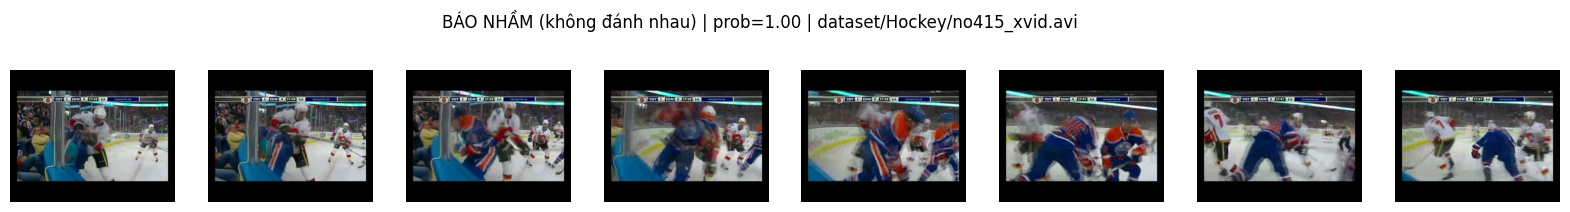

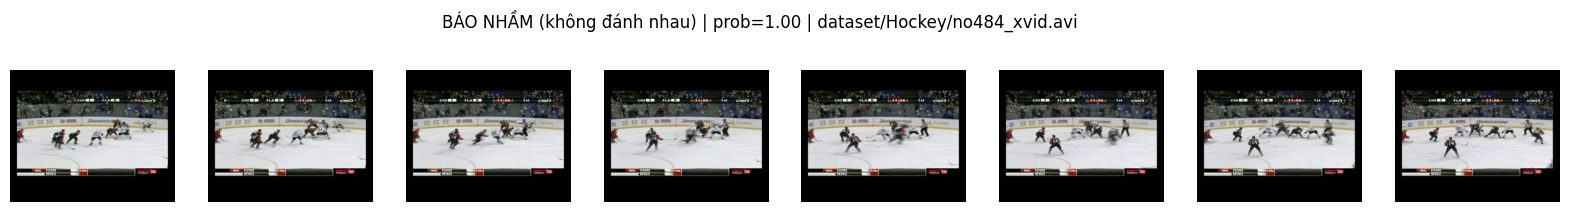

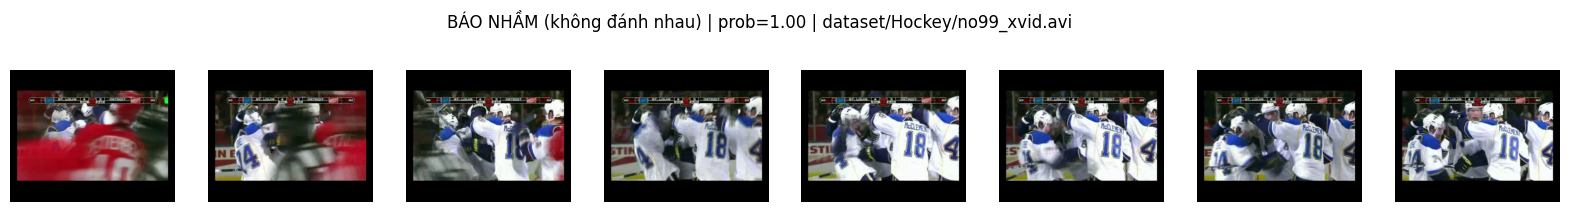

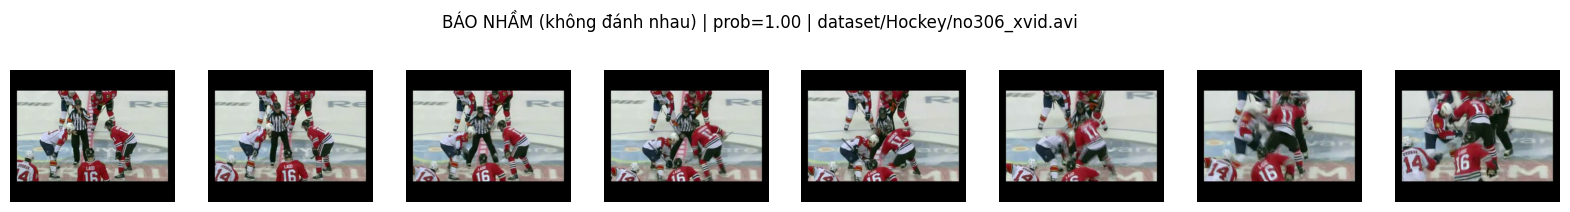

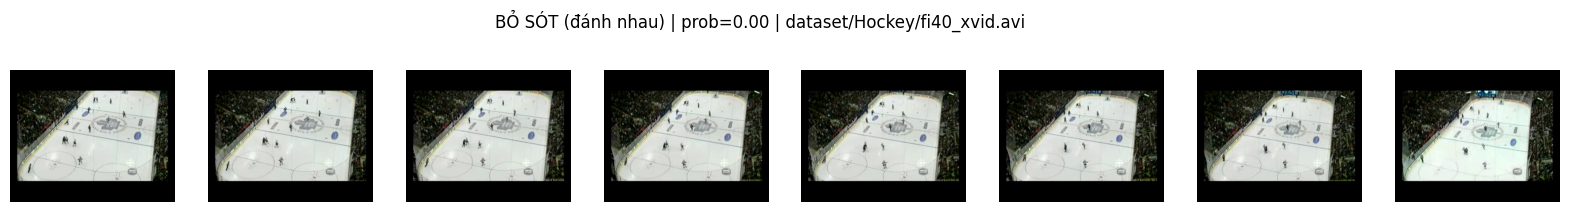

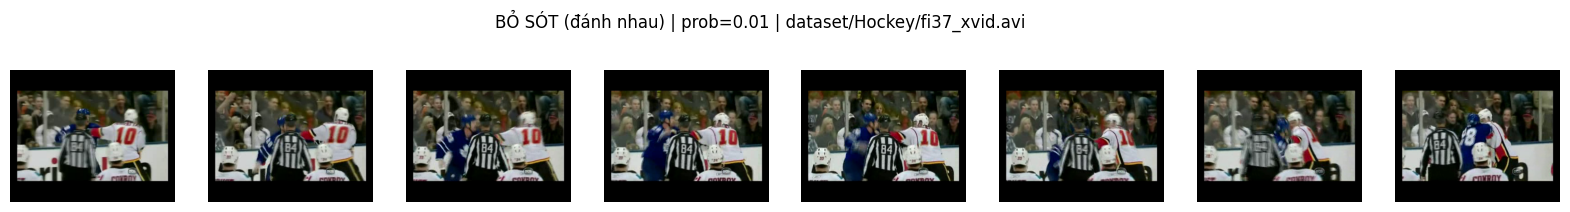

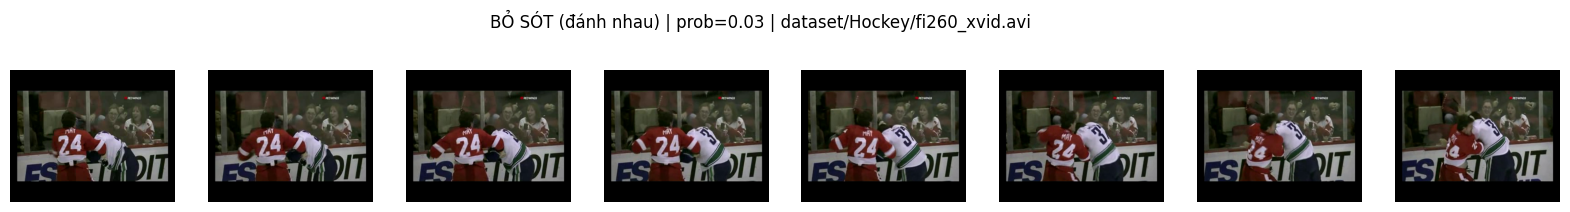

In [28]:
from sklearn.metrics import roc_auc_score
import numpy as np, cv2, matplotlib.pyplot as plt

p, y = predict(model, make_loader(hock_df, False))
out = hock_df.copy(); out['prob'] = p; out['pred'] = (p >= THR).astype(int)
out.to_csv(OUT_DIR / 'pred_hockey.csv', index=False)

print('AUC Hockey:', round(float(roc_auc_score(y, p)), 4), '| ngưỡng cố định =', round(float(THR), 2))
fp = out[(out.label == 0) & (out.pred == 1)].sort_values('prob', ascending=False)
fn = out[(out.label == 1) & (out.pred == 0)].sort_values('prob')
print(len(fp), 'báo nhầm |', len(fn), 'bỏ sót')

def show_clip(rel_path, title, n=8):
    cap = cv2.VideoCapture(str(DATA / rel_path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fig, ax = plt.subplots(1, n, figsize=(20, 2.6))
    for a, i in zip(ax, np.linspace(0, total - 1, n).astype(int)):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i)); ok, f = cap.read()
        if ok: a.imshow(cv2.cvtColor(f, cv2.COLOR_BGR2RGB))
        a.axis('off')
    cap.release(); fig.suptitle(title); plt.show()

for _, r in fp.head(4).iterrows():
    show_clip(r.path, f'BÁO NHẦM (không đánh nhau) | prob={r.prob:.2f} | {r.path}')
for _, r in fn.head(3).iterrows():
    show_clip(r.path, f'BỎ SÓT (đánh nhau) | prob={r.prob:.2f} | {r.path}')